# P5 cohort EDA — 09/11/2026

Snapshot P4 5.177 → cohort theo ledger được Phát cho phép, không sửa upstream.
85 ID được đánh giá trong review có giới hạn; 410 P2 và jobs ngoài queue vẫn **retained_unreviewed**.
Không gọi toàn cohort là verified IT, không suy rộng thành thị trường Việt Nam, không phân tích K/ML.
EDA 5.177 cũ ở `eda_p5_encoding.ipynb/.html` giữ làm historical evidence.


In [1]:
import hashlib, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display
import matplotlib.pyplot as plt

root = Path.cwd()
run = root / 'reports/preprocessing/05_encoding/p5_2026-11-09_cohort_v1'
out = root / 'data/preprocessing/05_encoding'
m = json.loads((out/'artifact_manifest.json').read_text())
metrics = json.loads((run/'metrics.json').read_text())
parent = json.loads((root/'reports/preprocessing/05_encoding/p5_2026-11-09_frozen_v2/metrics.json').read_text())
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
assert sha(root/'reports/preprocessing/05_encoding/snapshot_audit_2026-11-08/manifest.json') == m['input_manifest_sha256']
assert sha(root/m['vocabulary_path']) == m['vocabulary_sha256']
assert sha(root/m['cohort']['ledger_path']) == m['cohort']['ledger_sha256']
for artifact in m['current_artifacts']:
    assert sha(root/artifact['path']) == artifact['sha256']
assert pd.__version__ == m['environment']['pandas']
assert np.__version__ == m['environment']['numpy']
print('run_id:', m['run_id'], 'Python:', platform.python_version(), 'Pandas:', pd.__version__)
print('snapshot SHA:', m['input_manifest_sha256'])
print('ledger SHA:', m['cohort']['ledger_sha256'])
print('vocabulary SHA:', m['vocabulary_sha256'])


FileNotFoundError: [Errno 2] No such file or directory: '/home/phat/Downloads/2026/Data_mining/Project_Data_Mining/VN-IT-Job-Mining/notebooks/data/preprocessing/05_encoding/artifact_manifest.json'

## Cohort ledger và coverage review — từng ID được giải trình

disposition,exclude,include,quarantine
source,,,
careerviet,2,446,0
glints,2,269,0
itviec,0,905,0
jobsgo,2,681,0
topcv,19,1542,0
topdev,6,220,1
vieclam24h,0,180,2
vietnamworks,31,861,8


jobs
disposition review_status                    
exclude     excluded_by_approved_policy    62
include     retained_reviewed              12
            retained_unreviewed          5092
quarantine  unresolved_quarantined         11

Reviewed IDs: 85
P2 retained_unreviewed: 410; outside queue not_flagged_by_targeted_rules: 4682. Neither is verified IT.


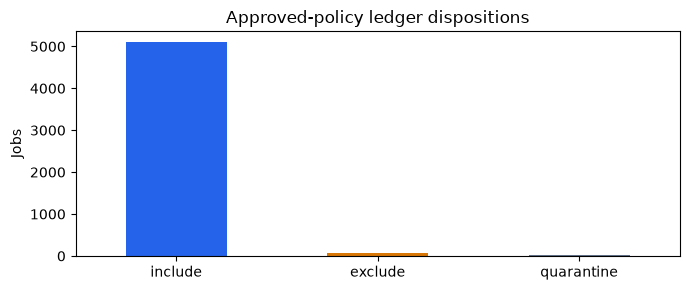

In [2]:
from preprocessing.encoding.execution_io import load_snapshot
_, p4, _ = load_snapshot(root/'reports/preprocessing/05_encoding/snapshot_audit_2026-11-08/manifest.json')
ledger = pd.read_csv(root/m['cohort']['ledger_path'], keep_default_na=False)
assert ledger.job_id_global.tolist() == p4.job_id_global.tolist()
assert ledger.job_id_global.is_unique
audit = ledger.assign(source=p4.source_platform.to_numpy())
display(pd.crosstab(audit.source, audit.disposition))
display(audit.groupby(['disposition','review_status']).size().rename('jobs').to_frame())
assert len(ledger)==5177 and ledger.disposition.eq('include').sum()==metrics['rows']
print('Reviewed IDs:', ledger.review_status.ne('retained_unreviewed').sum())
print('P2 retained_unreviewed: 410; outside queue not_flagged_by_targeted_rules: 4682. Neither is verified IT.')
fig, ax=plt.subplots(figsize=(7,3))
ledger.disposition.value_counts().reindex(['include','exclude','quarantine']).plot.bar(ax=ax,color=['#2563eb','#d97706','#64748b'])
ax.set(title='Approved-policy ledger dispositions',ylabel='Jobs',xlabel=''); ax.tick_params(axis='x',rotation=0)
plt.tight_layout(); plt.show()


## Frozen 230 features: frequency, skill/job, missing và all-zero

,canonical skills/job
count,5104.000000
mean,4.261364
std,4.085490
min,0.000000
25%,1.000000
50%,3.000000
75%,6.000000
max,26.000000


,jobs
null skills,0
empty skills,407
all-zero selected skills,873
unmatched-only,466


,canonical,column,jobs,skill_type,group
0,SQL,skill_sql,1761,hard,Programming Languages
1,REST API,skill_rest_api,1377,hard,Methodologies & Soft Skills
2,Python,skill_python,1067,hard,Programming Languages
3,Machine Learning,skill_machine_learning,1016,hard,NaN
4,Agile/Scrum,skill_agile_scrum,952,hard,Methodologies & Soft Skills
5,Git,skill_git,856,hard,"Tools, Architecture & Protocols"
6,CI/CD,skill_ci_cd,785,hard,Methodologies & Soft Skills
7,Docker,skill_docker,736,hard,Cloud & DevOps
8,Java,skill_java,655,hard,Programming Languages
9,AWS,skill_aws,618,hard,Cloud & DevOps


Zero-column skills: []


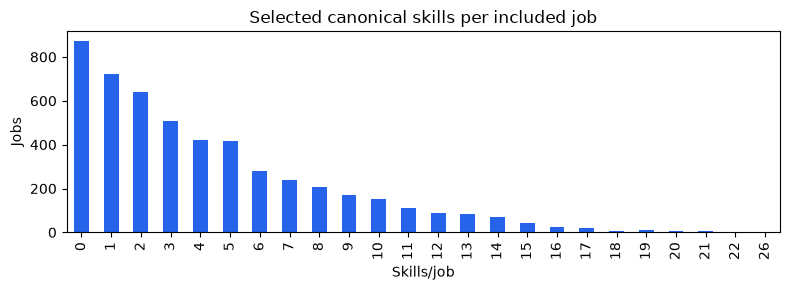

In [3]:
d = json.loads((out/'encoding_dictionary.json').read_text())
f = pd.read_parquet(out/'features.parquet')
columns=d['skill_columns']
X=f[columns]
included_ids=ledger.loc[ledger.disposition.eq('include'),'job_id_global'].tolist()
denied=set(ledger.loc[ledger.disposition.ne('include'),'job_id_global'])
assert f.job_id_global.tolist()==included_ids and not denied.intersection(f.job_id_global)
assert X.shape==(len(included_ids),230) and X.isin([0,1]).all().all()
skill_counts=X.sum(axis=1)
display(skill_counts.describe().to_frame('canonical skills/job'))
display(pd.DataFrame({'jobs':[int(f.skills__missing.sum()),int(f.skills__empty.sum()),int(skill_counts.eq(0).sum()),int(((skill_counts==0)&(f.other_skills_count>0)).sum())]},index=['null skills','empty skills','all-zero selected skills','unmatched-only']))
items=d['skills']['taxonomy']
freq=pd.DataFrame({'canonical':[i['canonical'] for i in items],'column':columns,'jobs':X.sum().to_numpy(),'skill_type':[i['skill_type'] for i in items],'group':[i['group'] for i in items]})
display(freq.sort_values(['jobs','canonical'],ascending=[False,True]).head(25))
print('Zero-column skills:',freq.loc[freq.jobs.eq(0),'canonical'].tolist())
fig, ax=plt.subplots(figsize=(8,3))
skill_counts.value_counts().sort_index().plot.bar(ax=ax,color='#2563eb')
ax.set(title='Selected canonical skills per included job',xlabel='Skills/job',ylabel='Jobs')
plt.tight_layout(); plt.show()


## Coverage và metadata — mẫu số và representation rõ

In [4]:
covered=int(X.any(axis=1).sum())
source_pairs=metrics['source_value_pairs']
unmatched=metrics['unmatched_source_pairs']
display(pd.DataFrame([{'metric':'job coverage','numerator':covered,'denominator':len(f),'ratio':covered/len(f)}, {'metric':'source-value-pair coverage','numerator':source_pairs-unmatched,'denominator':source_pairs,'ratio':(source_pairs-unmatched)/source_pairs}]))
print('Canonical pairs:',int(X.to_numpy().sum()),'; unmatched source pairs:',unmatched)
print('Representation: frozen whole-value casefold canonical+explicit aliases; each canonical counted once/job.')
display(freq.groupby('skill_type').size().to_frame('vocabulary columns'))
display(freq.groupby('group',dropna=False).size().to_frame('vocabulary columns'))
print('Null group is metadata gap, NOT a seventh task group or soft-skill label; group is not job_family.')
print('Below20:',int(freq.jobs.lt(20).sum()),'— allowed for this run, no padding or replacement.')


,metric,numerator,denominator,ratio
0,job coverage,4231,5104,0.828958
1,source-value-pair coverage,21882,32793,0.667277


Canonical pairs: 21750 ; unmatched source pairs: 10911
Representation: frozen whole-value casefold canonical+explicit aliases; each canonical counted once/job.


,vocabulary columns
skill_type,
hard,214
soft,16


,vocabulary columns
group,
Cloud & DevOps,21
Databases & Caching,5
Frameworks & Libraries,17
Methodologies & Soft Skills,91
Programming Languages,22
"Tools, Architecture & Protocols",55
NaN,19


Null group is metadata gap, NOT a seventh task group or soft-skill label; group is not job_family.
Below20: 138 — allowed for this run, no padding or replacement.


## Co-occurrence, TF-IDF và sparse summary

In [5]:
C=pd.read_parquet(out/'skill_cooccurrence.parquet')
assert C.index.tolist()==columns and C.columns.tolist()==columns
assert C.to_numpy().dtype==np.int64 and np.array_equal(C.to_numpy(),C.to_numpy().T)
np.testing.assert_array_equal(np.diag(C),X.sum().to_numpy())
pairs=[(int(C.iloc[i,j]),columns[i],columns[j]) for i in range(230) for j in range(i+1,230)]
display(pd.DataFrame(sorted(pairs,key=lambda x:(-x[0],x[1],x[2]))[:10],columns=['jobs','skill_a','skill_b']))
T=sparse.load_npz(out/'tfidf_matrix.npz')
rows=pd.read_parquet(out/'tfidf_rows.parquet')
assert rows.job_id_global.tolist()==f.job_id_global.tolist() and T.shape[0]==len(f)
assert T.format=='csr' and T.dtype==np.float32 and np.isfinite(T.data).all() and (T.data>=0).all()
norms=np.sqrt(np.asarray(T.multiply(T).sum(axis=1)).ravel())
assert np.all(np.isclose(norms,0,atol=2e-6)|np.isclose(norms,1,atol=2e-6))
display(pd.DataFrame([{'rows':T.shape[0],'terms':T.shape[1],'nnz':T.nnz,'density':T.nnz/(T.shape[0]*T.shape[1]),'zero_rows':int((norms==0).sum()),'CSR_bytes':T.data.nbytes+T.indices.nbytes+T.indptr.nbytes}]))
print('TF-IDF refit on include cohort before fit; full-corpus exploratory view. Supervised downstream must refit train-only.')


,jobs,skill_a,skill_b
0,819,skill_sql,skill_rest_api
1,599,skill_sql,skill_python
2,545,skill_sql,skill_nosql
3,533,skill_rest_api,skill_git
4,507,skill_sql,skill_git
5,493,skill_rest_api,skill_ci_cd
6,477,skill_ci_cd,skill_docker
7,477,skill_git,skill_ci_cd
8,451,skill_sql,skill_docker
9,449,skill_sql,skill_ci_cd


,rows,terms,nnz,density,zero_rows,CSR_bytes
0,5104,3000,989799,0.064642,0,7938812


TF-IDF refit on include cohort before fit; full-corpus exploratory view. Supervised downstream must refit train-only.


## Trước/sau và remaining anomalies

In [6]:
comparison=pd.DataFrame({
 'historical5177':{'jobs':parent['rows'],'covered_jobs':parent['job_coverage']['numerator'],'job_coverage':parent['job_coverage']['numerator']/parent['rows'],'canonical_pairs':parent['canonical_pairs'],'sparsity':parent['sparsity'],'zero_columns':parent['zero_columns'],'below20':parent['below20']},
 'current_include':{'jobs':metrics['rows'],'covered_jobs':covered,'job_coverage':covered/len(f),'canonical_pairs':metrics['canonical_pairs'],'sparsity':metrics['sparsity'],'zero_columns':metrics['zero_columns'],'below20':metrics['below20']}
})
display(comparison)
q=pd.read_parquet(out/'data_quality.parquet')
display(q.reason.value_counts().to_frame('quality events, not unique jobs'))
print('Family values remain P4 source values; flagged questions live in sidecars, not automatic relabeling.')
print('Audit columns excluded from recommended salary predictors:',d['audit_columns'])
assert not set(d['recommended_predictors']['salary_regression']).intersection(d['audit_columns'])
print('P5 acceptance:',m['acceptance_status'],'; Python3.12 remains UNVERIFIED unless separately tested.')


,historical5177,current_include
jobs,5177.000000,5104.000000
covered_jobs,4277.000000,4231.000000
job_coverage,0.826154,0.828958
canonical_pairs,21845.000000,21750.000000
sparsity,0.981654,0.981472
zero_columns,0.000000,0.000000
below20,137.000000,138.000000


,"quality events, not unique jobs"
reason,
missing_numeric,9540
missing_days_to_deadline,1818
missing_posted_month,1739
missing,693
empty_array,407
unrecognized_employment_label,88
deadline_before_posted,8
autocad_presence_audit_no_auto_exclusion,3
min_gt_max_source_preserved,1


Family values remain P4 source values; flagged questions live in sidecars, not automatic relabeling.
Audit columns excluded from recommended salary predictors: ['autocad_scope_review', 'days_to_deadline__missing', 'deadline_before_posted', 'deadline_date__invalid', 'employment_type__missing', 'employment_type__unknown', 'exp_max_years__missing', 'exp_min_years__missing', 'exp_range_invalid', 'headcount__missing', 'is_foreign__missing', 'is_negotiable__missing', 'is_outlier_salary', 'is_outlier_salary__missing', 'is_remote__missing', 'it_rule_level__2', 'it_rule_level__2__missing', 'job_family__missing', 'job_family__unknown', 'job_family_can_kiem', 'job_family_can_kiem__missing', 'locations__empty', 'locations__missing', 'log_salary_max__missing', 'log_salary_min__missing', 'other_skills_count', 'posted_date__invalid', 'posted_month__missing', 'seniority__missing', 'seniority__unknown', 'seniority_can_kiem', 'seniority_can_kiem__missing', 'skills__empty', 'skills__missing', 'source_pla

## Giới hạn và handoff

85 reviewed IDs are policy-based Agent assessments or owner-approved decisions, not a human gold-label dataset.
410 P2 and 4.682 outside-queue jobs are intentionally retained_unreviewed; residual scope contamination is possible.
11 quarantine rows stay in immutable P4/ledger and are not confirmed non-IT.
No upstream filter/job_family/dictionary was repaired. Frozen skill counts from 5.177 remain reference counts;
current observed counts are separate. Scope is this collected snapshot, not all Vietnam IT labor demand.
Use manifest+ledger hashes and dictionary.skill_columns, align TF-IDF by row IDs; do not include audit/target-derived
salary columns in supervised predictors. Python3.12/whole-repo test limitations are reported separately.
